In [1]:
from pathlib import Path
import json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import norm
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
ROOT = Path("causal_ope_outputs")
for sub in ("figures", "reports", "data"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
SEED = 20261107
N = 1800
REPS = 60
FOLDS = 3
ALPHA = 0.05
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 180, "axes.spines.top": False, "axes.spines.right": False})
print("JAX", jax.__version__, "| NumPy", np.__version__, "| Python", platform.python_version())
print("Output directory:", ROOT.resolve())


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\themi\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\themi\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\themi\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\themi\anaconda3\Lib\site-pack

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\themi\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\themi\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\themi\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\themi\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



JAX 0.12.0.1 | NumPy 2.5.4 | Python 3.12.3
Output directory: C:\Users\themi\Documents\GitHub\trustworthy-causal-modelling\causal_ope_outputs


## Simulated decisions

Workload still drives the energy outcome, but now there is a choice between two actions.

I included settings with poor overlap and hidden confounding to see where the estimates break down.

In [2]:
@jax.jit
def jax_mu(u, a):
    return 1.0 + 1.5*u + 0.5*u*u + a*(2.3 + 0.5*u + 0.4*jnp.sin(u))

def mu(u, a):
    return np.asarray(jax_mu(jnp.asarray(u), jnp.asarray(a)))

def target_policy(u):
    return expit(-0.3 + 0.9*np.asarray(u))

def logging_policy(u, gamma=0.8, intercept=-0.2):
    return expit(intercept + gamma*np.asarray(u))

def sample_data(seed, n=N, setting="standard"):
    rng = np.random.default_rng(seed)
    shift = 0.8 if setting == "covariate_shift" else 0.0
    u = rng.normal(shift, 1.0, n)
    gamma = 3.8 if setting == "weak_overlap" else 0.8
    b = logging_policy(u, gamma)
    a = rng.binomial(1, b)
    hidden = rng.normal(size=n)
    if setting == "hidden_confounding":
        # Hidden common cause of action and outcome, omitted from observed covariates
        b = expit(-0.2 + 0.8*u + 1.4*hidden)
        a = rng.binomial(1, b)
        y = mu(u, a) + 1.2*hidden + rng.normal(size=n)
    else:
        y = mu(u, a) + rng.normal(size=n)
    return pd.DataFrame({"u":u, "a":a, "y":y, "b_true":b, "pi":target_policy(u)})

example = sample_data(SEED)
display(example.head())
print("Observed action-1 fraction:", round(example.a.mean(), 3))

,u,a,y,b_true,pi
0,0.457973,0,1.374219,0.541499,0.528014
1,-1.094971,0,0.743142,0.254268,0.216620
2,0.265012,1,2.758801,0.503002,0.484632
3,-0.313866,1,2.160574,0.389101,0.358362
4,-0.186175,1,2.763618,0.413640,0.385195


Observed action-1 fraction: 0.456


## Ground truth

A separate, much larger simulation gives the reference policy values.

That gives us something concrete to compare the estimates against.

In [3]:
def oracle_values(setting="standard", seed=99173, size=300_000):
    rng = np.random.default_rng(seed)
    shift = 0.8 if setting == "covariate_shift" else 0.0
    u = rng.normal(shift, 1, size)
    pi = target_policy(u)
    if setting == "hidden_confounding":
        # Integrate the latent H out of the action mechanism
        h = rng.normal(size=(size, 4))
        b = expit(-0.2 + 0.8*u[:,None] + 1.4*h).mean(axis=1)
    else:
        b = logging_policy(u, 3.8 if setting == "weak_overlap" else 0.8)
    m0, m1 = mu(u, np.zeros(size)), mu(u, np.ones(size))
    return {"target":float(np.mean((1-pi)*m0 + pi*m1)),
            "logging":float(np.mean((1-b)*m0 + b*m1))}
SETTINGS = ["standard", "weak_overlap", "covariate_shift", "hidden_confounding"]
ORACLE = {s:oracle_values(s) for s in SETTINGS}
print(pd.DataFrame(ORACLE).T.round(4))

                    target  logging
standard            2.6436   2.6778
weak_overlap        2.6436   2.8847
covariate_shift     4.8341   4.8418
hidden_confounding  2.6436   2.6720


## Estimation models

I fitted the action probabilities and the outcomes separately.

Cross fitting keeps each observation out of the models used to evaluate it.

In [4]:
def feature_matrix(u, kind="outcome"):
    u = np.asarray(u, float)
    if kind == "propensity":
        return np.column_stack([np.ones(len(u)), u])
    return np.column_stack([np.ones(len(u)), u, u*u, np.sin(u), np.cos(u)])

def ridge_fit(X, y, lam=1.0):
    penalty = np.eye(X.shape[1]); penalty[0,0] = 0
    return np.linalg.solve(X.T@X + lam*penalty, X.T@y)

def logistic_fit(X, a, lam=1.0, iterations=40):
    beta = np.zeros(X.shape[1]); penalty = np.eye(X.shape[1]); penalty[0,0] = 0
    for _ in range(iterations):
        p = np.clip(expit(X@beta), 1e-5, 1-1e-5)
        H = X.T@((p*(1-p))[:,None]*X) + lam*penalty
        step = np.linalg.solve(H, X.T@(a-p) - lam*penalty@beta)
        beta += np.clip(step, -2, 2)
        if np.max(np.abs(step)) < 1e-7: break
    return beta

def crossfit(df, seed=123, folds=FOLDS):
    n = len(df); rng = np.random.default_rng(seed)
    indices = np.array_split(rng.permutation(n), folds)
    u, a, y = df.u.to_numpy(), df.a.to_numpy(), df.y.to_numpy()
    Xp, Xm = feature_matrix(u,"propensity"), feature_matrix(u)
    p = np.empty(n); m0 = np.empty(n); m1 = np.empty(n)
    for test in indices:
        train = np.setdiff1d(np.arange(n), test, assume_unique=True)
        bp = logistic_fit(Xp[train], a[train]); p[test] = expit(Xp[test]@bp)
        for action, arr in [(0,m0),(1,m1)]:
            ids = train[a[train] == action]
            if len(ids) < Xm.shape[1] + 3:
                raise ValueError("Insufficient observations in an action arm")
            bm = ridge_fit(Xm[ids],y[ids],lam=2.0)
            arr[test] = Xm[test]@bm
    return p,m0,m1

def estimate(df, seed=123, clip=0.02):
    p,m0,m1 = crossfit(df,seed)
    a,y,pi = df.a.to_numpy(),df.y.to_numpy(),df.pi.to_numpy()
    p_safe = np.clip(p,clip,1-clip)
    q = np.where(a==1,p_safe,1-p_safe)
    t = np.where(a==1,pi,1-pi)
    w = t/q
    m_pi = (1-pi)*m0 + pi*m1
    ipw = w*y
    dr = m_pi + w*(y - np.where(a==1,m1,m0))
    # Baseline value: sample mean under the observed logging policy (valid if observed population representative)
    # For hidden confounding, observational mean is not an interventional logging-policy oracle.
    baseline = float(np.mean(y))
    values = {"naive":float(np.mean(y)), "dm":float(np.mean(m_pi)),
              "ipw":float(np.mean(ipw)), "snipw":float(np.sum(w*y)/np.sum(w)),
              "dr":float(np.mean(dr))}
    # Fixed-nuisance Wald intervals: useful empirical benchmark, not finite-sample guarantees
    scores = {"naive":y,"dm":m_pi,"ipw":ipw,"snipw":(w*(y-values["snipw"]))/np.mean(w),"dr":dr}
    se = {k:float(np.std(v,ddof=1)/np.sqrt(len(y))) for k,v in scores.items()}
    ess = float(np.sum(w)**2/np.sum(w*w))
    return values,se,ess,{"propensity":p,"weights":w,"dr_scores":dr,"m_pi":m_pi,"baseline":baseline}

values,se,ess,details = estimate(example)
print(pd.DataFrame({"estimate":values,"se":se}).round(4))
print(f"Importance-weight ESS: {ess:.1f} / {len(example)} ({ess/len(example):.1%})")

       estimate      se
naive    2.6192  0.0639
dm       2.6041  0.0551
ipw      2.6038  0.0668
snipw    2.6012  0.0669
dr       2.6021  0.0601
Importance-weight ESS: 1781.9 / 1800 (99.0%)


## First comparison

Starting with one logged dataset, I compared direct estimation, importance weighting and the doubly robust estimate.

The plots make the differences easier to see.

,estimator,estimate,bias_vs_oracle,CI_low,CI_high,oracle
0,NAIVE,2.6192,-0.0243,2.4940,2.7445,2.6436
1,DM,2.6041,-0.0395,2.4961,2.7122,2.6436
2,IPW,2.6038,-0.0398,2.4729,2.7347,2.6436
3,SNIPW,2.6012,-0.0424,2.4700,2.7324,2.6436
4,DR,2.6021,-0.0415,2.4842,2.7200,2.6436


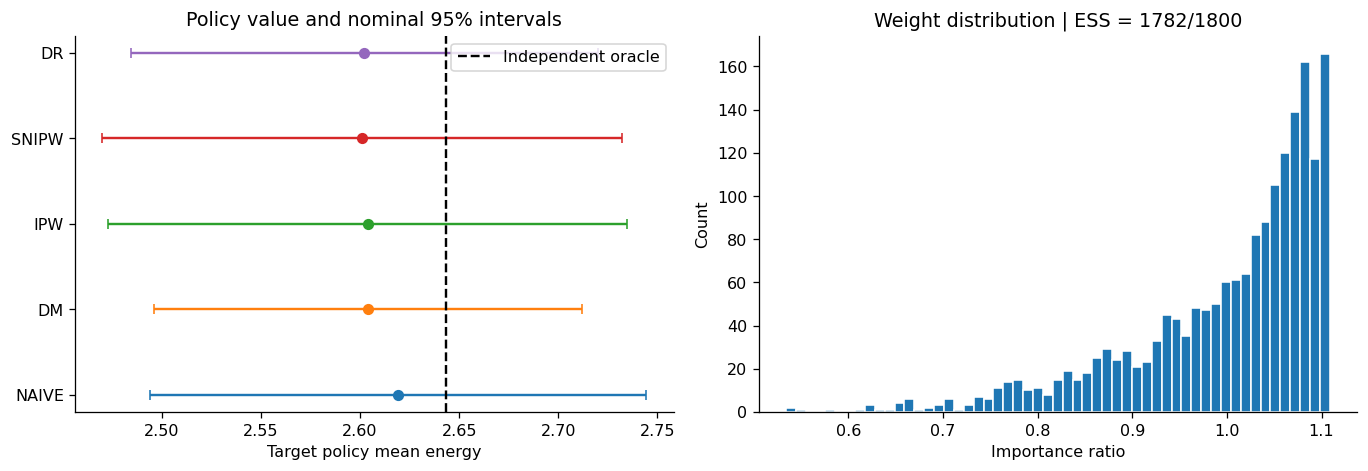

In [5]:
truth = ORACLE["standard"]["target"]
rows=[]
for name,v in values.items():
    rows.append({"estimator":name.upper(),"estimate":v,"bias_vs_oracle":v-truth,
                 "CI_low":v-1.96*se[name],"CI_high":v+1.96*se[name],
                 "oracle":truth})
one = pd.DataFrame(rows)
display(one.round(4))
one.to_csv(ROOT/"reports"/"single_sample_estimators.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
ax=axes[0]
for i,r in one.iterrows():
    ax.errorbar(r.estimate,i,xerr=1.96*se[r.estimator.lower()],fmt="o",capsize=3)
ax.axvline(truth,ls="--",color="black",label="Independent oracle")
ax.set_yticks(range(len(one)),one.estimator);ax.set_xlabel("Target policy mean energy");ax.set_title("Policy value and nominal 95% intervals");ax.legend()
ax=axes[1];ax.hist(details["weights"],bins=55,edgecolor="white")
ax.set_xlabel("Importance ratio");ax.set_ylabel("Count");ax.set_title(f"Weight distribution | ESS = {ess:.0f}/{N}")
fig.tight_layout();fig.savefig(ROOT/"figures"/"01_point_estimates_and_weights.png");plt.show()

## Repeating the experiment

The results from a single dataset vary with the random draw.

I repeated the experiment with fresh data and recorded bias, RMSE and interval coverage.

In [6]:
def run_benchmark(settings=SETTINGS,reps=REPS,n=N):
    records=[]; start=time.time()
    for setting in settings:
        target = ORACLE[setting]["target"]
        for rep in range(reps):
            df = sample_data(SEED+100_000*SETTINGS.index(setting)+rep,n,setting)
            v,s,e,_ = estimate(df,seed=rep+733)
            for method in v:
                low,high = v[method]-1.96*s[method],v[method]+1.96*s[method]
                records.append({"setting":setting,"rep":rep,"method":method,"estimate":v[method],
                                "oracle":target,"error":v[method]-target,"se":s[method],
                                "covered":int(low<=target<=high),"interval_width":high-low,"ess":e})
        print(f"{setting}: {reps} repetitions complete")
    print(f"Elapsed: {time.time()-start:.1f} s")
    return pd.DataFrame(records)

results = run_benchmark()
results.to_csv(ROOT/"data"/"monte_carlo_results.csv",index=False)
summary = (results.groupby(["setting","method"])
    .agg(bias=("error","mean"),rmse=("error",lambda x:float(np.sqrt(np.mean(np.square(x))))),
         coverage=("covered","mean"),mean_CI_width=("interval_width","mean"),
         mean_ESS=("ess","mean"),replications=("rep","nunique")).reset_index())
summary["coverage_MC_SE"] = np.sqrt(summary.coverage*(1-summary.coverage)/summary.replications)
summary.to_csv(ROOT/"reports"/"benchmark_summary.csv",index=False)
display(summary.round(3))

standard: 60 repetitions complete
weak_overlap: 60 repetitions complete
covariate_shift: 60 repetitions complete
hidden_confounding: 60 repetitions complete
Elapsed: 0.9 s


,setting,method,bias,rmse,coverage,mean_CI_width,mean_ESS,replications,coverage_MC_SE
0,covariate_shift,dm,0.020,0.080,0.917,0.302,1794.562,60,0.036
1,covariate_shift,dr,0.019,0.080,0.950,0.316,1794.562,60,0.028
2,covariate_shift,ipw,0.026,0.083,0.950,0.341,1794.562,60,0.028
3,covariate_shift,naive,0.029,0.085,0.983,0.336,1794.562,60,0.017
4,covariate_shift,snipw,0.019,0.081,0.950,0.342,1794.562,60,0.028
5,hidden_confounding,dm,-0.031,0.079,0.867,0.230,1766.017,60,0.044
6,hidden_confounding,dr,-0.030,0.079,0.917,0.267,1766.017,60,0.036
7,hidden_confounding,ipw,-0.026,0.077,0.950,0.316,1766.017,60,0.028
8,hidden_confounding,naive,0.036,0.087,0.917,0.299,1766.017,60,0.036
9,hidden_confounding,snipw,-0.030,0.079,0.967,0.319,1766.017,60,0.023


## Looking at the errors

Here I put the estimator results side by side.

The error and coverage plots give a clearer picture than one successful run.

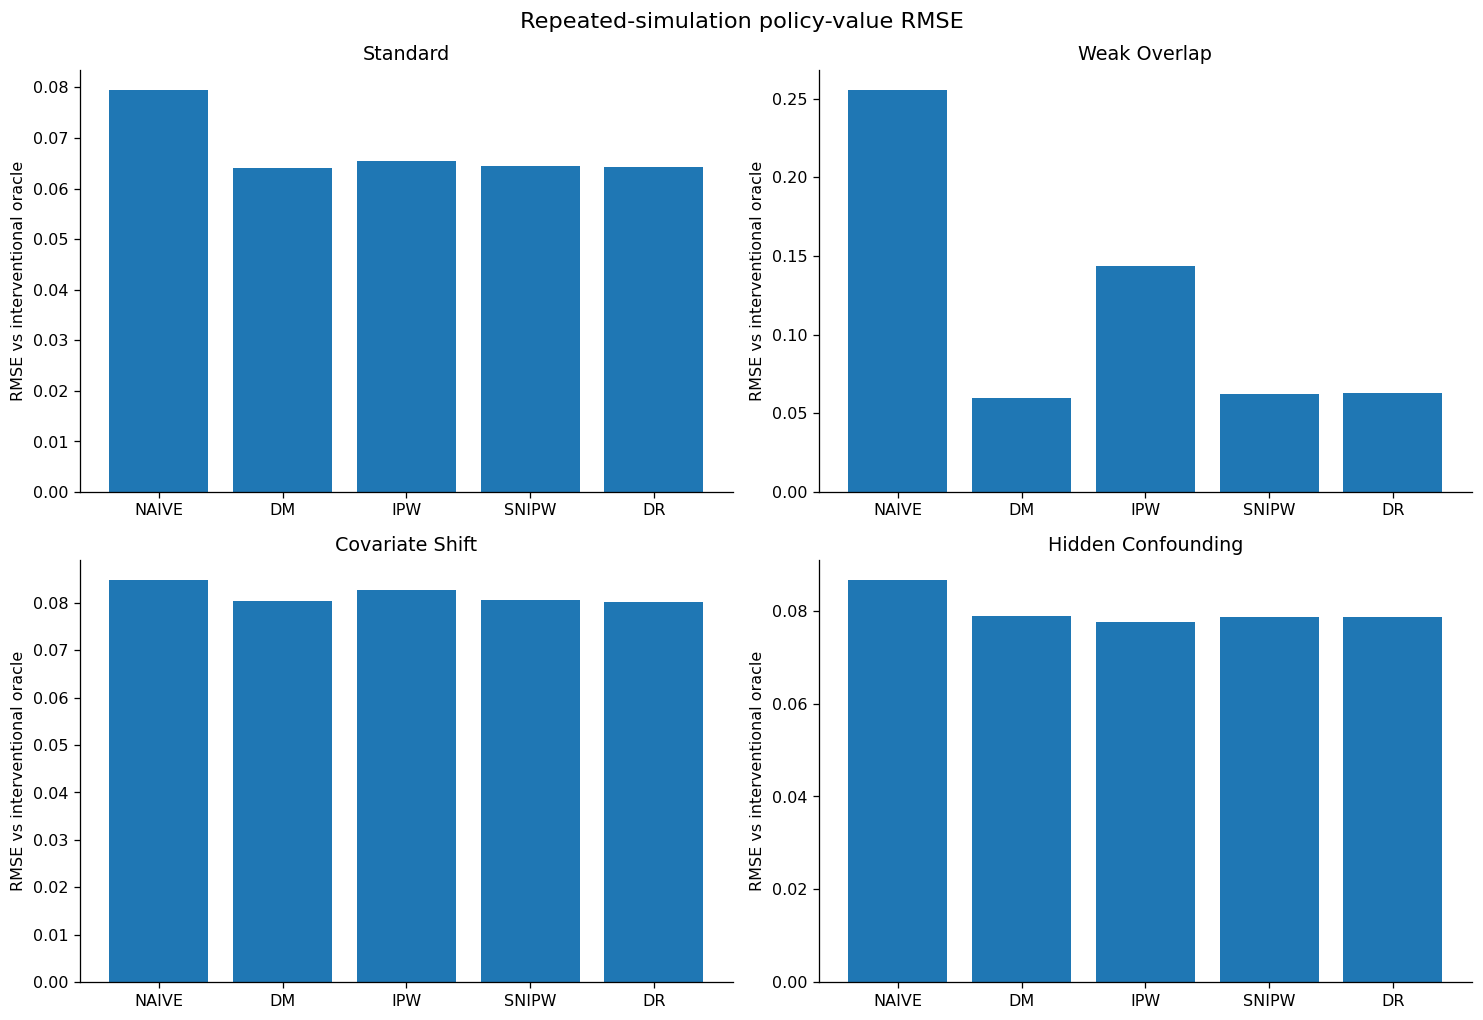

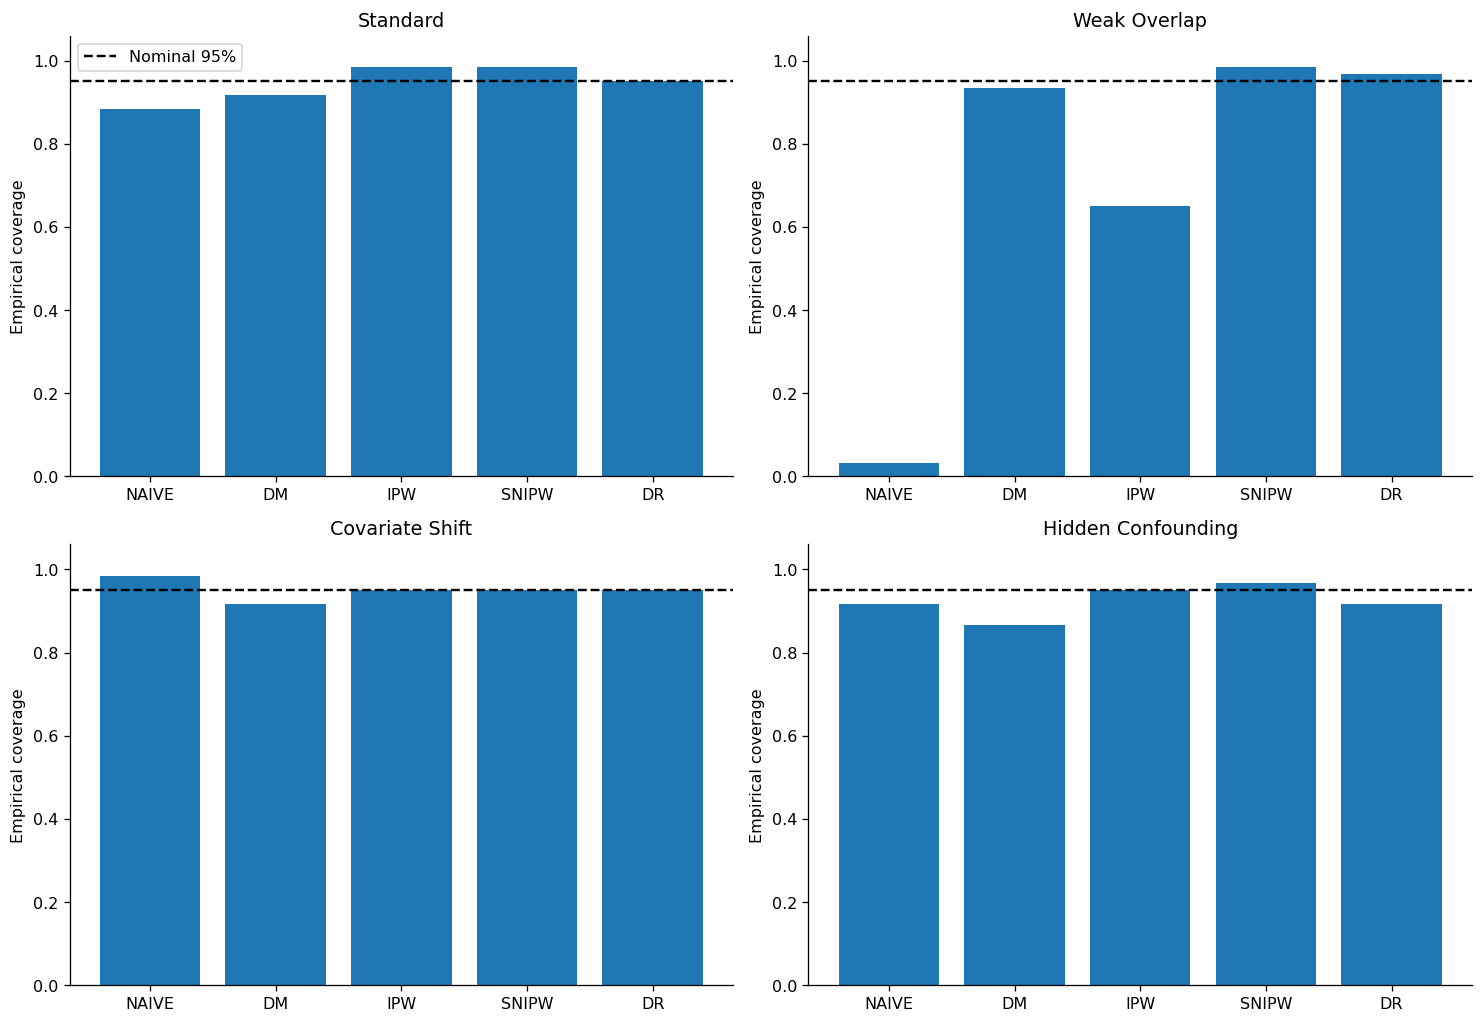

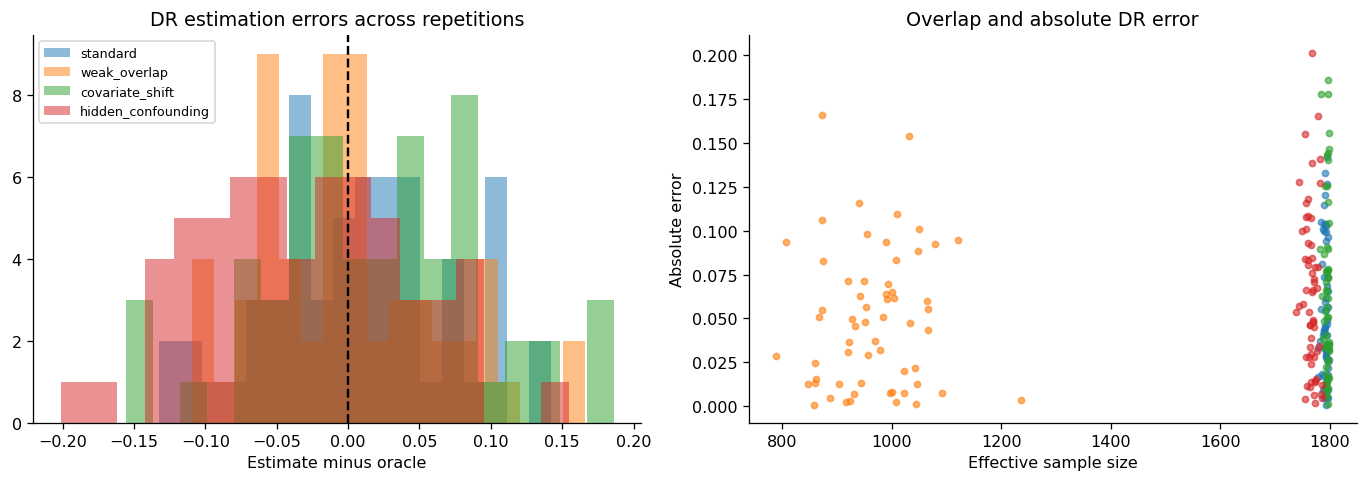

In [7]:
methods=["naive","dm","ipw","snipw","dr"]
fig,axes=plt.subplots(2,2,figsize=(13,9))
for i,setting in enumerate(SETTINGS):
    ax=axes.flat[i];sub=summary[summary.setting==setting].set_index("method").loc[methods]
    ax.bar(np.arange(len(methods)),sub.rmse.to_numpy());ax.set_xticks(np.arange(len(methods)),[x.upper() for x in methods]);
    ax.set_ylabel("RMSE vs interventional oracle");ax.set_title(setting.replace("_"," ").title())
fig.suptitle("Repeated-simulation policy-value RMSE",fontsize=14);fig.tight_layout();fig.savefig(ROOT/"figures"/"02_rmse_by_setting.png");plt.show()

fig,axes=plt.subplots(2,2,figsize=(13,9))
for i,setting in enumerate(SETTINGS):
    ax=axes.flat[i];sub=summary[summary.setting==setting].set_index("method").loc[methods]
    ax.bar(np.arange(len(methods)),sub.coverage.to_numpy());ax.axhline(.95,ls="--",color="black",label="Nominal 95%")
    ax.set_ylim(0,1.06);ax.set_xticks(np.arange(len(methods)),[x.upper() for x in methods]);ax.set_ylabel("Empirical coverage")
    ax.set_title(setting.replace("_"," ").title())
axes.flat[0].legend();fig.tight_layout();fig.savefig(ROOT/"figures"/"03_interval_coverage.png");plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4.3))
for setting in SETTINGS:
    sub=results[(results.setting==setting)&(results.method=="dr")]
    axes[0].hist(sub.error,bins=18,alpha=.5,label=setting)
axes[0].axvline(0,color="black",ls="--");axes[0].set_title("DR estimation errors across repetitions")
axes[0].set_xlabel("Estimate minus oracle");axes[0].legend(fontsize=8)
for setting in SETTINGS:
    sub=results[(results.setting==setting)&(results.method=="dr")]
    axes[1].scatter(sub.ess,abs(sub.error),s=15,alpha=.6,label=setting)
axes[1].set_title("Overlap and absolute DR error");axes[1].set_xlabel("Effective sample size");axes[1].set_ylabel("Absolute error")
fig.tight_layout();fig.savefig(ROOT/"figures"/"04_errors_and_ess.png");plt.show()

## Limited overlap

Some actions barely appear in the logged data.

I checked the propensity distributions and the weights to see how much information remains.

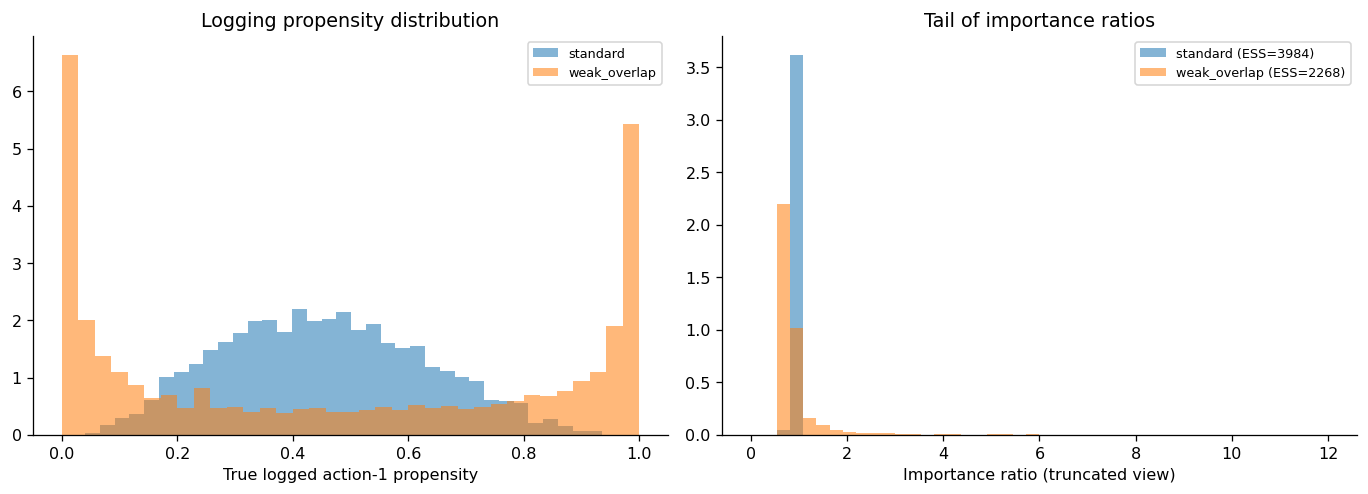

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for setting in ["standard","weak_overlap"]:
    d=sample_data(SEED+3,4000,setting)
    axes[0].hist(d.b_true,bins=35,alpha=.55,label=setting,density=True)
    _,_,e,dt=estimate(d,seed=3)
    axes[1].hist(dt["weights"],bins=np.linspace(0,12,45),alpha=.55,label=f"{setting} (ESS={e:.0f})",density=True)
axes[0].set_xlabel("True logged action-1 propensity");axes[0].set_title("Logging propensity distribution")
axes[1].set_xlabel("Importance ratio (truncated view)");axes[1].set_title("Tail of importance ratios")
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(ROOT/"figures"/"05_overlap_diagnostics.png");plt.show()

## Sensitivity tests

Next I varied the clipping level and the amount of data.

The plots track how the estimates change across those settings.

,setting,clip,bias,rmse,ess
0,standard,0.005,0.003,0.078,1192.509
1,standard,0.020,0.003,0.078,1192.509
2,standard,0.050,0.003,0.078,1192.509
3,standard,0.100,0.003,0.078,1192.478
4,weak_overlap,0.005,-0.012,0.088,538.833
5,weak_overlap,0.020,-0.008,0.083,682.099
6,weak_overlap,0.050,-0.009,0.082,834.186
7,weak_overlap,0.100,-0.011,0.078,973.757


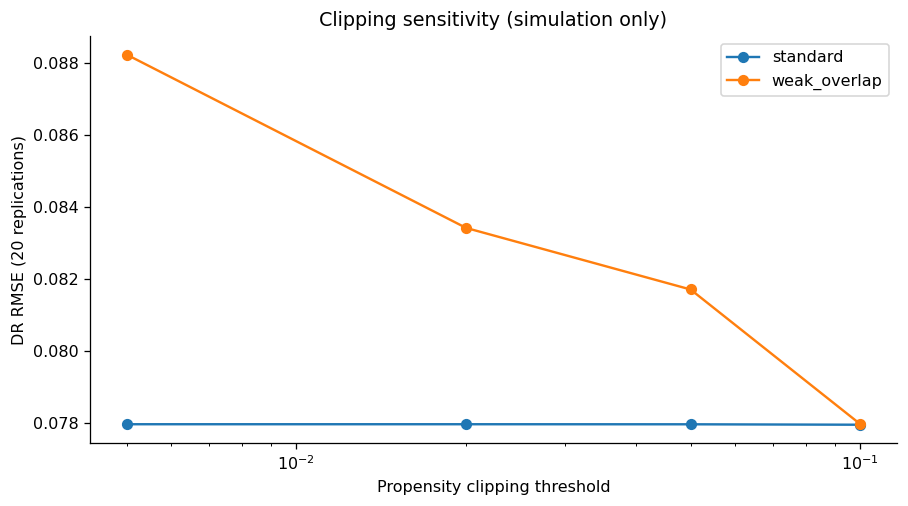

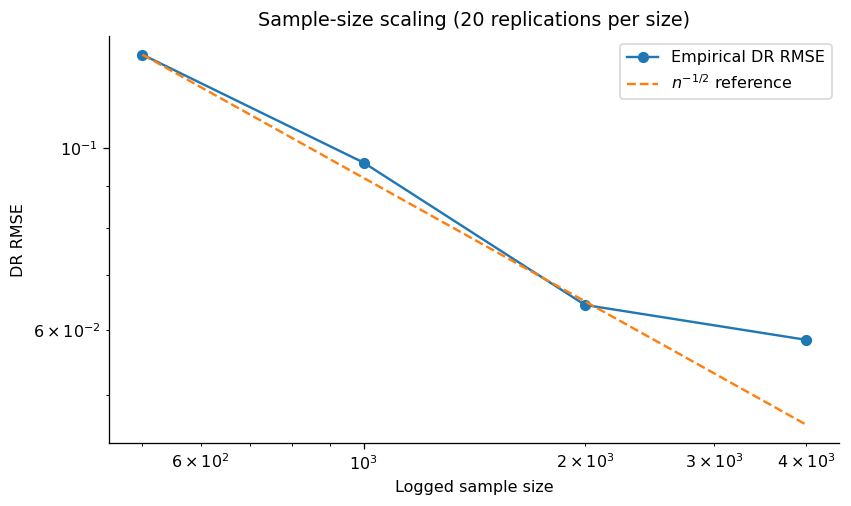

In [9]:
clips=[0.005,0.02,0.05,0.1]
clip_rows=[]
for setting in ["standard","weak_overlap"]:
    for rep in range(20):
        d=sample_data(80000+1000*SETTINGS.index(setting)+rep,1200,setting)
        for clip in clips:
            v,_,e,_=estimate(d,seed=rep+100,clip=clip)
            clip_rows.append({"setting":setting,"clip":clip,"rep":rep,"dr_error":v["dr"]-ORACLE[setting]["target"],"ess":e})
clip_df=pd.DataFrame(clip_rows)
clip_summary=clip_df.groupby(["setting","clip"]).agg(bias=("dr_error","mean"),rmse=("dr_error",lambda x:np.sqrt(np.mean(x*x))),ess=("ess","mean")).reset_index()
clip_summary.to_csv(ROOT/"reports"/"clipping_sensitivity.csv",index=False)
display(clip_summary.round(3))
fig,ax=plt.subplots(figsize=(8,4.5))
for setting,g in clip_summary.groupby("setting"):
    ax.plot(g["clip"],g.rmse,"o-",label=setting)
ax.set_xscale("log");ax.set_xlabel("Propensity clipping threshold");ax.set_ylabel("DR RMSE (20 replications)");ax.legend();ax.set_title("Clipping sensitivity (simulation only)")
fig.tight_layout();fig.savefig(ROOT/"figures"/"06_clipping_sensitivity.png");plt.show()

sizes=[500,1000,2000,4000]
size_rows=[]
for size in sizes:
    for rep in range(20):
        d=sample_data(400000+rep,size,"standard")
        v,_,_,_=estimate(d,seed=rep+31)
        size_rows.append({"n":size,"rep":rep,"dr_error":v["dr"]-ORACLE["standard"]["target"]})
size_df=pd.DataFrame(size_rows)
size_summary=size_df.groupby("n").agg(rmse=("dr_error",lambda x:np.sqrt(np.mean(x*x))),bias=("dr_error","mean")).reset_index()
size_summary.to_csv(ROOT/"reports"/"sample_size_sensitivity.csv",index=False)
fig,ax=plt.subplots(figsize=(7.5,4.5));ax.loglog(size_summary.n,size_summary.rmse,"o-",label="Empirical DR RMSE")
ax.loglog(size_summary.n,size_summary.rmse.iloc[0]*np.sqrt(sizes[0]/size_summary.n),"--",label=r"$n^{-1/2}$ reference")
ax.set_xlabel("Logged sample size");ax.set_ylabel("DR RMSE");ax.set_title("Sample-size scaling (20 replications per size)");ax.legend()
fig.tight_layout();fig.savefig(ROOT/"figures"/"07_sample_size_scaling.png");plt.show()

## Policy comparison

Now the question is the difference between the new policy and the one that generated the data.

I used a paired estimate and calculated its confidence interval from the same sample.

,setting,oracle_delta,mean_estimate,bias,rmse,coverage,mean_ESS
0,covariate_shift,-0.0077,-0.0120,-0.0043,0.0345,0.9429,1793.2994
1,hidden_confounding,-0.0284,-0.0606,-0.0322,0.0511,0.8857,1766.9211
2,standard,-0.0342,-0.0345,-0.0003,0.0317,0.9143,1791.0953
3,weak_overlap,-0.2411,-0.2437,-0.0026,0.0483,0.8571,983.3396


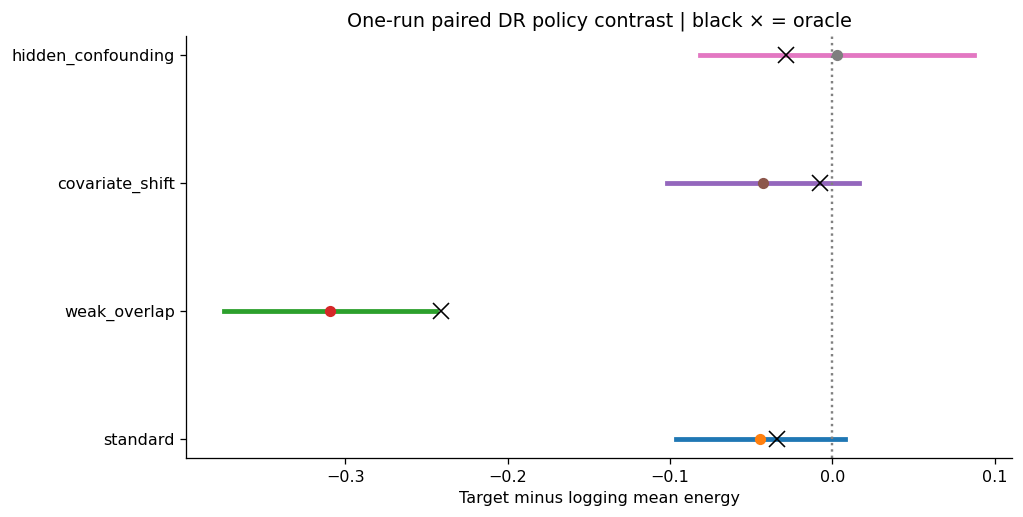

In [10]:
contrast_rows=[]
for setting in ["standard","weak_overlap","covariate_shift","hidden_confounding"]:
    for rep in range(35):
        d=sample_data(900000+rep+10000*SETTINGS.index(setting),N,setting)
        v,s,e,details=estimate(d,seed=rep+99)
        score=details["dr_scores"]-d.y.to_numpy()
        delta=float(score.mean()); sd=float(score.std(ddof=1)/np.sqrt(len(score)))
        oracle_delta=ORACLE[setting]["target"]-ORACLE[setting]["logging"]
        contrast_rows.append({"setting":setting,"rep":rep,"delta_hat":delta,"oracle_delta":oracle_delta,
                              "error":delta-oracle_delta,"CI_low":delta-1.96*sd,"CI_high":delta+1.96*sd,
                              "covered":int(abs(delta-oracle_delta)<=1.96*sd),"ESS":e})
contrast=pd.DataFrame(contrast_rows)
contrast.to_csv(ROOT/"data"/"policy_contrasts.csv",index=False)
contrast_summary=contrast.groupby("setting").agg(oracle_delta=("oracle_delta","first"),mean_estimate=("delta_hat","mean"),
 bias=("error","mean"),rmse=("error",lambda x:np.sqrt(np.mean(x*x))),coverage=("covered","mean"),mean_ESS=("ESS","mean")).reset_index()
display(contrast_summary.round(4))
contrast_summary.to_csv(ROOT/"reports"/"policy_contrast_summary.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4.6))
for i,setting in enumerate(SETTINGS):
    r=contrast[contrast.setting==setting].iloc[0]
    ax.plot([r.CI_low,r.CI_high],[i,i],lw=3);ax.plot(r.delta_hat,i,"o")
    ax.plot(r.oracle_delta,i,"x",color="black",ms=10)
ax.axvline(0,ls=":",color="grey");ax.set_yticks(range(len(SETTINGS)),SETTINGS)
ax.set_xlabel("Target minus logging mean energy");ax.set_title("One-run paired DR policy contrast | black × = oracle")
fig.tight_layout();fig.savefig(ROOT/"figures"/"08_policy_contrasts.png");plt.show()

## Checking the evidence

I looked at whether the interval crosses zero and how much effective sample size is left.

Both are reported with the estimated policy difference.

In [11]:
def decide(row, n=N, ess_fraction=0.25):
    if row.ESS/n < ess_fraction:
        return "ABSTAIN: low effective sample size"
    if row.CI_low <= 0 <= row.CI_high:
        return "ABSTAIN: interval crosses zero"
    return "TARGET LOWER ENERGY" if row.CI_high < 0 else "LOGGING LOWER ENERGY"
examples=contrast.groupby("setting",sort=False).head(1).copy()
examples["decision"]=examples.apply(decide,axis=1)
display(examples[["setting","delta_hat","CI_low","CI_high","ESS","decision"]].round(3))
examples.to_csv(ROOT/"reports"/"decision_examples.csv",index=False)

,setting,delta_hat,CI_low,CI_high,ESS,decision
0,standard,-0.044,-0.097,0.008,1792.648,ABSTAIN: interval crosses zero
35,weak_overlap,-0.310,-0.375,-0.244,1220.219,TARGET LOWER ENERGY
70,covariate_shift,-0.043,-0.102,0.016,1795.610,ABSTAIN: interval crosses zero
105,hidden_confounding,0.003,-0.082,0.088,1763.289,ABSTAIN: interval crosses zero
